# 05 Logistic Regression

## 1. Import Libraries and Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc, confusion_matrix
import seaborn as sns
from imblearn.over_sampling import SMOTE

df = pd.read_csv("data/processed_dataset.csv")
df = pd.get_dummies(df.drop(columns=['customerID']), drop_first=True)

X = df.drop(columns=['Churn_Yes'])
y = df['Churn_Yes']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)


## 2. SMOTE & Training

Classification Report:
              precision    recall  f1-score   support

       False       0.92      0.72      0.81      1036
        True       0.51      0.82      0.63       373

    accuracy                           0.75      1409
   macro avg       0.71      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409



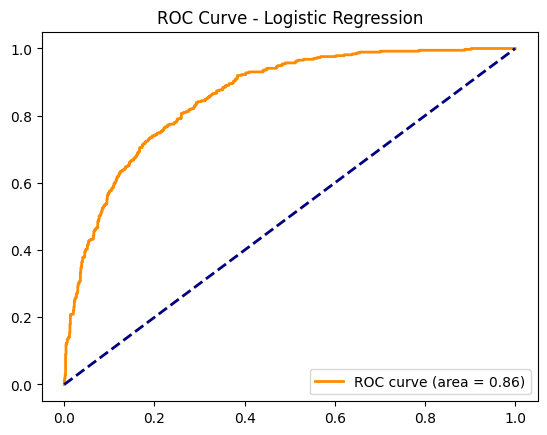

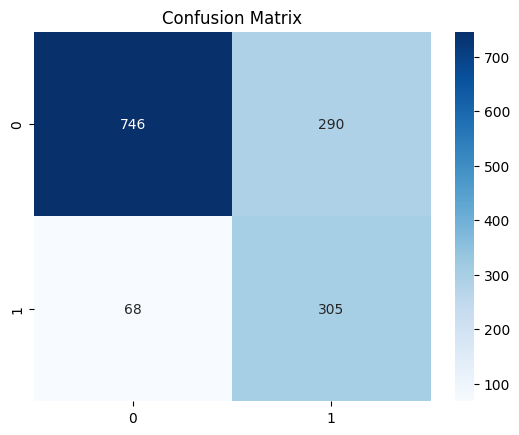

In [2]:

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train_sc, y_train)

logreg = LogisticRegression(random_state=42, max_iter=1000)
logreg.fit(X_train_sm, y_train_sm)

y_pred = logreg.predict(X_test_sc)
y_prob = logreg.predict_proba(X_test_sc)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.title('ROC Curve - Logistic Regression')
plt.legend(loc="lower right")
plt.savefig('plots/05_roc_curve.png')
plt.show()

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.savefig('plots/05_confusion_matrix.png')
plt.show()
